In [1]:
import sys

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

Python Version: 3.11.18 (main, Oct 26 2026, 18:15:19) [Clang 20.1.8 ]
Python Executable: /opt/anaconda3/envs/churn-analysis/bin/python


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries are working!")

Pandas: 3.0.6
NumPy: 2.4.6
Scikit-learn: 1.9.1
All libraries are working!


# Customer Churn Analysis

### Data Analysis and Machine Learning Project

**Objective:** Analyze customer behavior, identify factors influencing customer churn, and develop a machine learning model to predict customers who are likely to leave.

**Tools & Technologies**
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook
- Power BI (for dashboard development)

**Project Workflow**
1. Data Loading and Understanding
2. Data Cleaning and Preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Machine Learning Model Development
6. Model Evaluation
7. Customer Risk Segmentation
8. Business Insights and Recommendations

## 1. Importing Libraries

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

In [4]:
# Load the customer churn dataset
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2.1 Dataset Dimensions

In [5]:
# Check the number of rows and columns
df.shape

(7043, 21)

In [6]:
# Display all column names
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [7]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 2.2 Checking Missing Values

In [8]:
# Count missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# Calculate the percentage of missing values
(df.isnull().sum() / len(df)) * 100

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

### 2.3 Checking Duplicate Records

In [10]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

In [11]:
# Check duplicate customer IDs
df["customerID"].duplicated().sum()

np.int64(0)

### 2.4 Checking Unique Values

In [13]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include=["str", "object"]).columns

# Display unique values
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


customerID:
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection:
<StringArray>
['No', 'Yes', 'No internet 

### 2.5 Numerical Column Inspection

In [14]:
# Display descriptive statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 3. Data Cleaning and Preprocessing

### 3.1 Checking Data Types

In [15]:
# Check the current data type of TotalCharges
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

### 3.2 Converting TotalCharges to Numeric

In [16]:
# Convert TotalCharges from string to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check the updated data type
df["TotalCharges"].dtype

dtype('float64')

In [17]:
# Count missing values after conversion
df["TotalCharges"].isnull().sum()

np.int64(11)

### 3.3 Investigating Missing TotalCharges

In [18]:
# Display customer records with missing TotalCharges
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [19]:
# Check the tenure of customers with missing TotalCharges
df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


### 3.4 Handling Missing Values

The 11 missing values in TotalCharges correspond to customers with zero tenure. Since these customers have not accumulated any charges, the missing values are replaced with zero.

In [20]:
# Replace missing TotalCharges values with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
df["TotalCharges"].isnull().sum()

np.int64(0)

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 3.5 Checking Missing Values Across the Dataset

In [22]:
# Check missing values in every column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [23]:
# Calculate the total number of missing values
df.isnull().sum().sum()

np.int64(0)

In [24]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [25]:
# Check the number of rows and columns
df.shape

(7043, 21)

In [26]:
# Check column data types and dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [27]:
# Create a separate copy for Power BI
dashboard_df = df.copy()

In [28]:
# Save the cleaned dataset for Power BI
cleaned_path = "/Users/macreset/Downloads/customer-churn-analytics/data/cleaned/Telco-Customer-Churn_Cleaned.csv"

dashboard_df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved successfully!")
print(cleaned_path)

Cleaned dataset saved successfully!
/Users/macreset/Downloads/customer-churn-analytics/data/cleaned/Telco-Customer-Churn_Cleaned.csv


## 4. Exploratory Data Analysis (EDA)

### 4.1 Overall Customer Analysis

In [29]:
# Calculate overall customer KPIs

total_customers = df.shape[0]

churned_customers = (df["Churn"] == "Yes").sum()

retained_customers = (df["Churn"] == "No").sum()

churn_rate = (churned_customers / total_customers) * 100

retention_rate = (retained_customers / total_customers) * 100

total_revenue = df["TotalCharges"].sum()

churned_revenue = df.loc[
    df["Churn"] == "Yes", "TotalCharges"
].sum()

print("CUSTOMER CHURN ANALYSIS")
print("-----------------------")
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")
print("Total Revenue:", round(total_revenue, 2))
print("Revenue from Churned Customers:", round(churned_revenue, 2))

CUSTOMER CHURN ANALYSIS
-----------------------
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %
Retention Rate: 73.46 %
Total Revenue: 16056168.7
Revenue from Churned Customers: 2862926.9


### 4.2 Key Business Observations

1. The dataset contains 7,043 customers, of which 1,869 have discontinued the service.
2. The overall customer churn rate is 26.54%, indicating that approximately one in four customers has left.
3. The customer retention rate is 73.46%.
4. The total recorded customer charges amount to 16,056,168.70.
5. Customers who churned contributed 2,862,926.90 in recorded lifetime charges.

**Business Implication:** The company should investigate the factors contributing to customer churn and develop targeted retention strategies to reduce customer loss.

### 4.3 Customer Churn Distribution

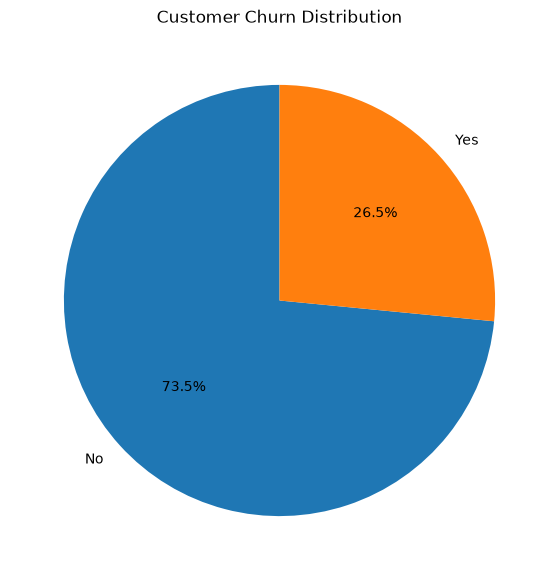

In [30]:
# Count customers by churn status
churn_counts = df["Churn"].value_counts()

# Create a pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn Distribution")
plt.show()

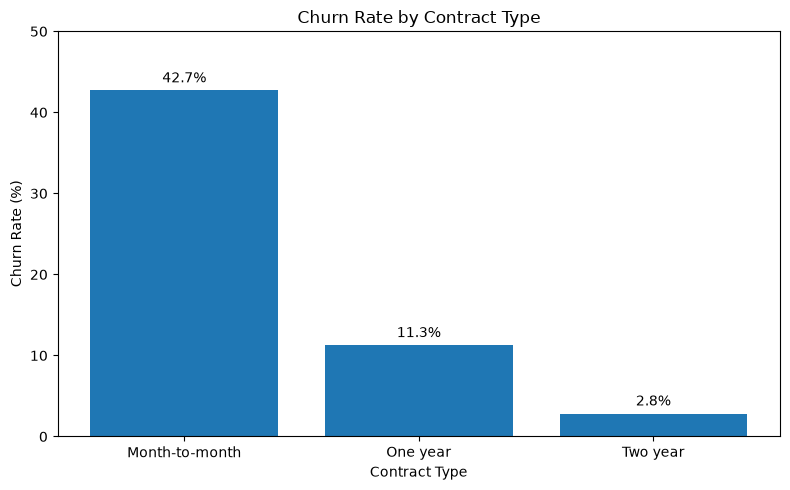

In [31]:
# Calculate churn rate by contract type
contract_churn = (
    df.groupby("Contract", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(contract_churn.index, contract_churn.values)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

# Display percentages above bars
for i, value in enumerate(contract_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [33]:
# Create customer tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Early", "Established", "Long-term"]
)

# Check the groups
df["TenureGroup"].value_counts()

TenureGroup
Long-term      2239
New            2186
Established    1594
Early          1024
Name: count, dtype: int64

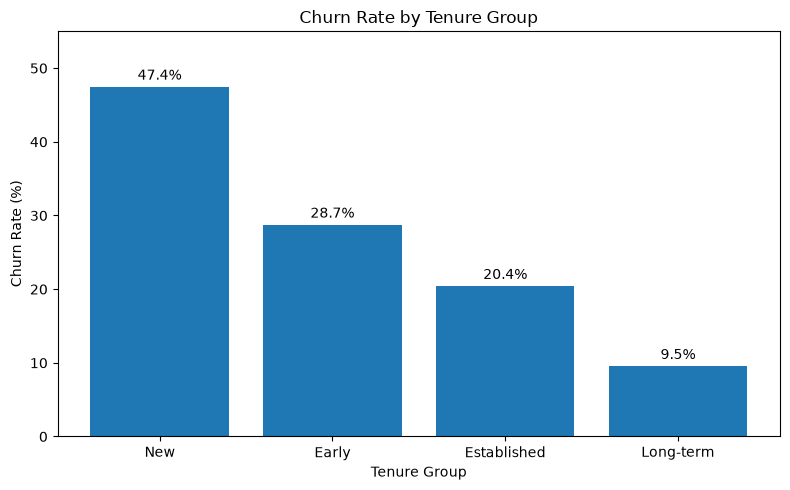

In [34]:
# Calculate churn rate by tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(tenure_churn.index.astype(str), tenure_churn.values)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(tenure_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 55)
plt.tight_layout()
plt.show()

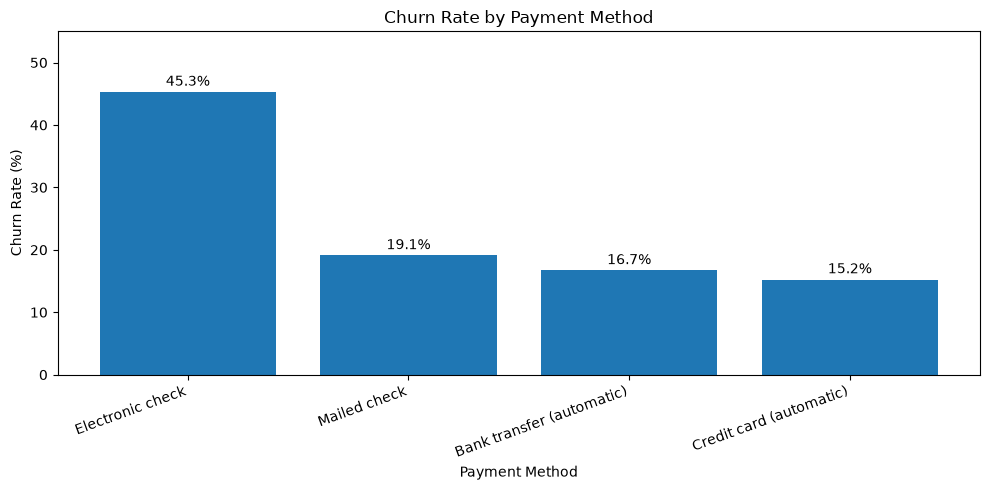

In [35]:
# Calculate churn rate by payment method
payment_churn = (
    df.groupby("PaymentMethod", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(payment_churn.index, payment_churn.values)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

# Display percentages
for i, value in enumerate(payment_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 55)
plt.tight_layout()
plt.show()

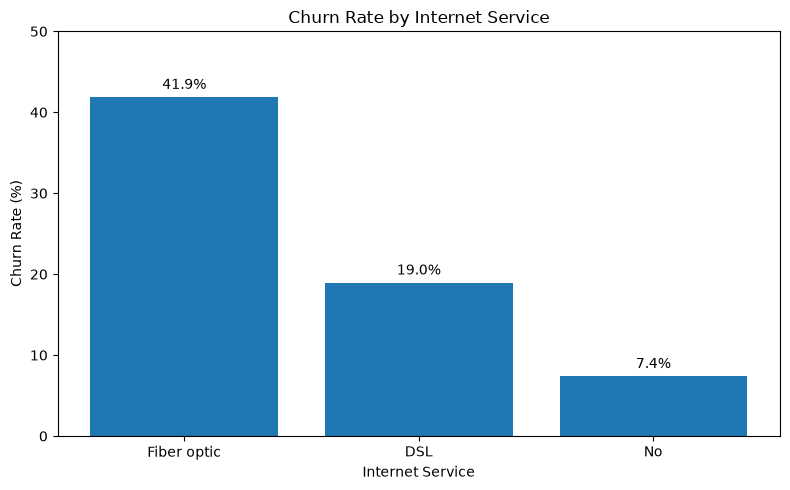

In [36]:
# Calculate churn rate by internet service
internet_churn = (
    df.groupby("InternetService", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(internet_churn.index, internet_churn.values)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(internet_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

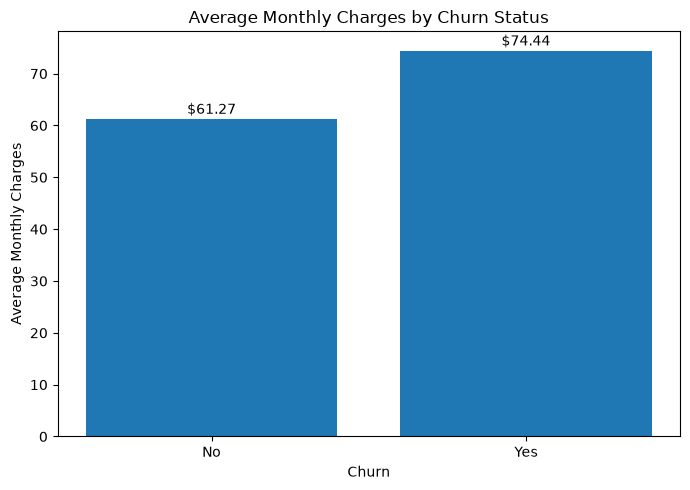

In [37]:
# Calculate average monthly charges by churn status
monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].mean()

# Plot the results
plt.figure(figsize=(7, 5))
bars = plt.bar(monthly_charges_churn.index, monthly_charges_churn.values)

plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"${bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

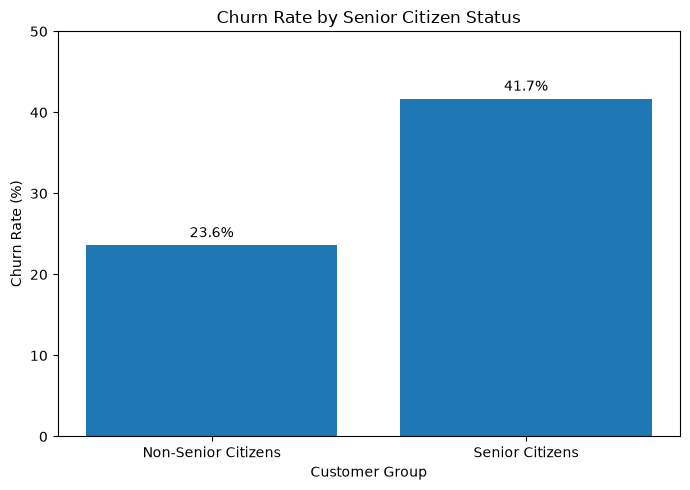

In [38]:
# Calculate churn rate by senior citizen status
senior_churn = (
    df.groupby("SeniorCitizen")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Non-Senior Citizens", "Senior Citizens"],
    senior_churn.values
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Group")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

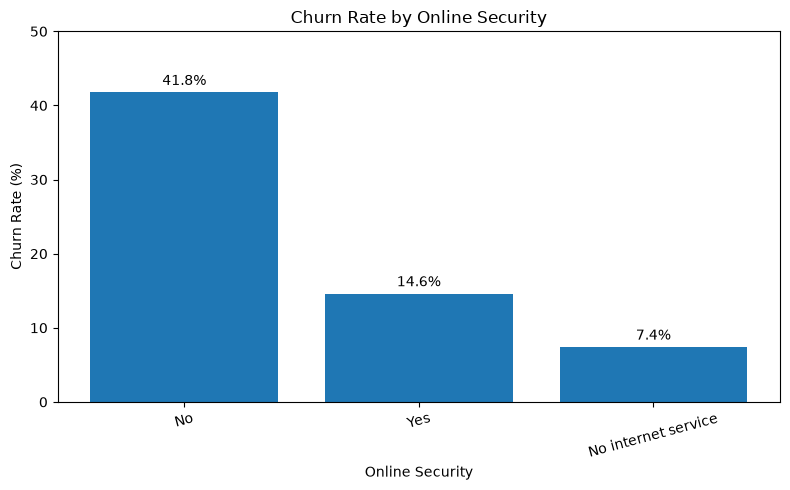

In [39]:
# Calculate churn rate by online security
security_churn = (
    df.groupby("OnlineSecurity")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(8, 5))

bars = plt.bar(
    security_churn.index,
    security_churn.values
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

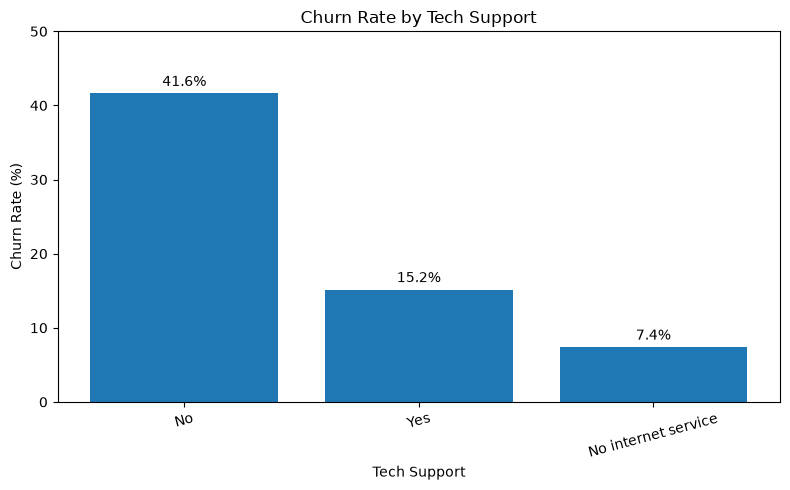

In [40]:
# Calculate churn rate by technical support
support_churn = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(8, 5))

bars = plt.bar(
    support_churn.index,
    support_churn.values
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

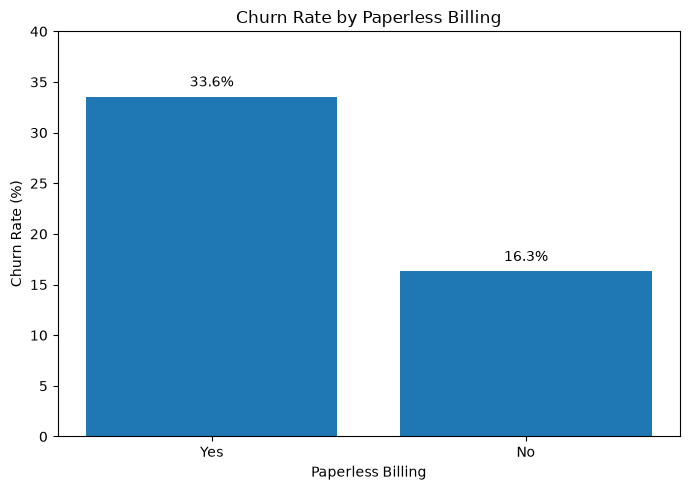

In [41]:
# Calculate churn rate by paperless billing
billing_churn = (
    df.groupby("PaperlessBilling")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    billing_churn.index,
    billing_churn.values
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 40)
plt.tight_layout()
plt.show()

Key finding
- Paperless Billing – Yes: 33.6% churn rate
- Paperless Billing – No: 16.3% churn rate
Customers using paperless billing have approximately 2.1 times the churn rate of customers who do not.

Business insight: Customers enrolled in paperless billing show a higher churn rate. This may be worth investigating alongside their contract type, payment method, and service preferences. This is an association, not proof that paperless billing causes churn.

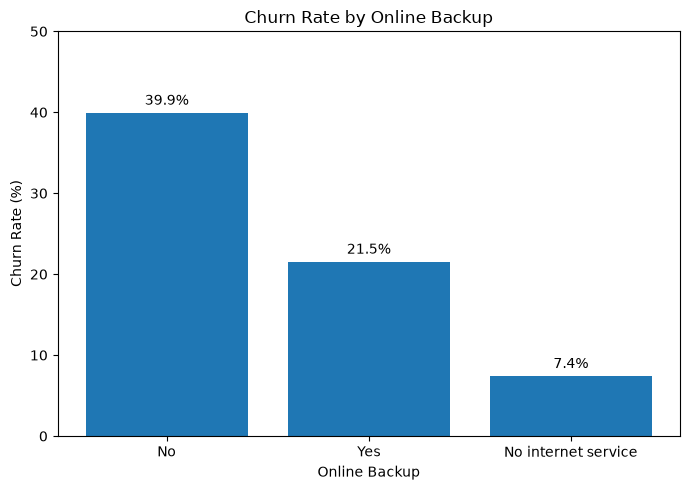

In [42]:
# Calculate churn rate by online backup
backup_churn = (
    df.groupby("OnlineBackup")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    backup_churn.index,
    backup_churn.values
)

plt.title("Churn Rate by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

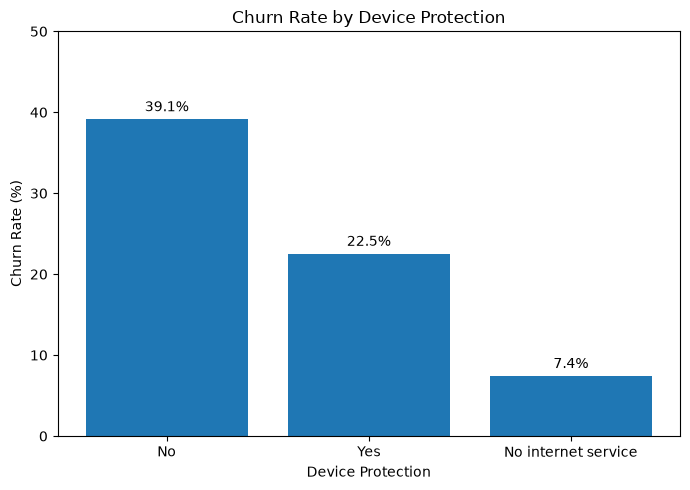

In [43]:
# Calculate churn rate by device protection
protection_churn = (
    df.groupby("DeviceProtection")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    protection_churn.index,
    protection_churn.values
)

plt.title("Churn Rate by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

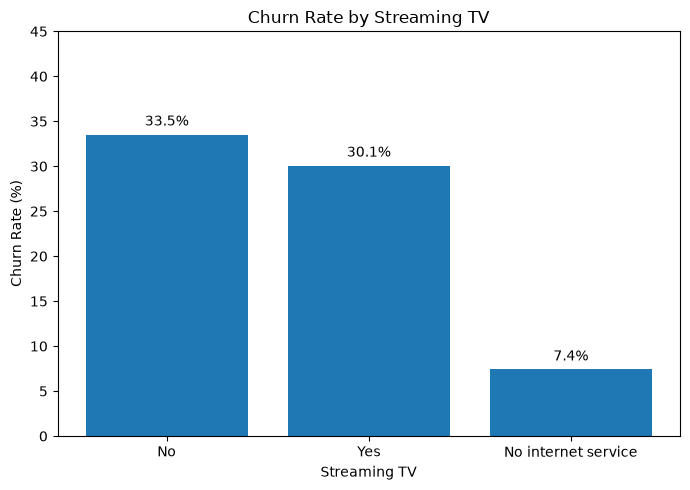

In [44]:
# Calculate churn rate by Streaming TV
streaming_tv_churn = (
    df.groupby("StreamingTV")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    streaming_tv_churn.index,
    streaming_tv_churn.values
)

plt.title("Churn Rate by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 45)
plt.tight_layout()
plt.show()

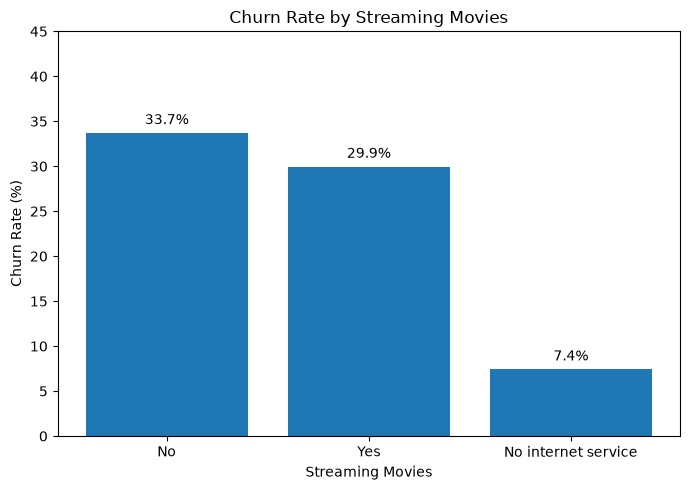

In [45]:
# Calculate churn rate by Streaming Movies
streaming_movies_churn = (
    df.groupby("StreamingMovies")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    streaming_movies_churn.index,
    streaming_movies_churn.values
)

plt.title("Churn Rate by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 45)
plt.tight_layout()
plt.show()

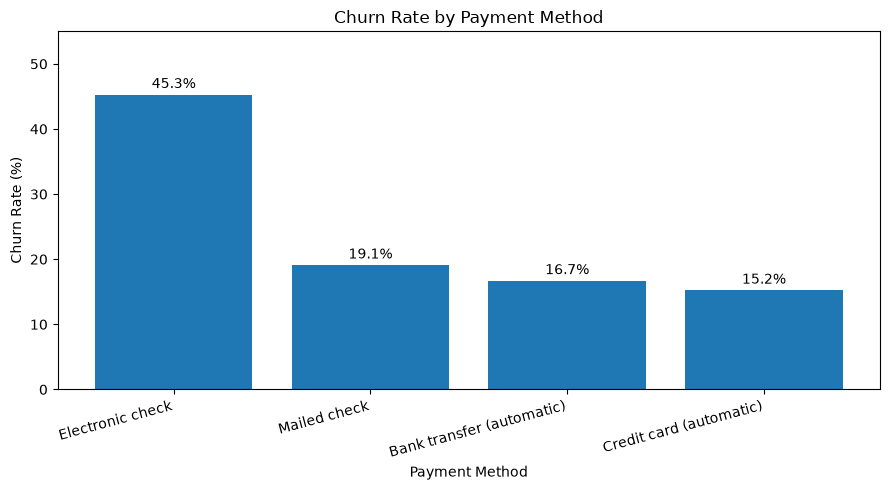

In [46]:
# Calculate churn rate by payment method
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(9, 5))

bars = plt.bar(
    payment_churn.index,
    payment_churn.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 55)
plt.tight_layout()
plt.show()

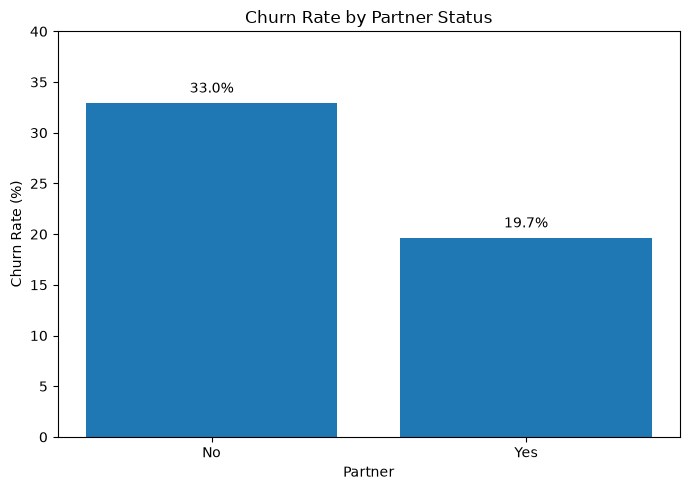

In [47]:
# Calculate churn rate by partner status
partner_churn = (
    df.groupby("Partner")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    partner_churn.index,
    partner_churn.values
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 40)
plt.tight_layout()
plt.show()

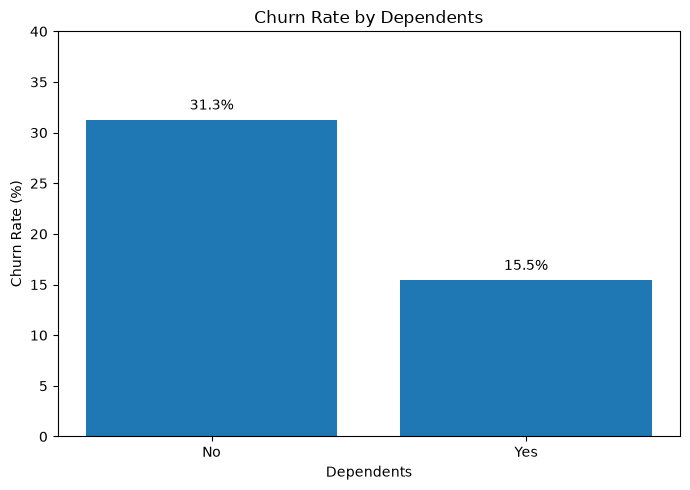

In [48]:
# Calculate churn rate by dependent status
dependents_churn = (
    df.groupby("Dependents")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    dependents_churn.index,
    dependents_churn.values
)

plt.title("Churn Rate by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 40)
plt.tight_layout()
plt.show()

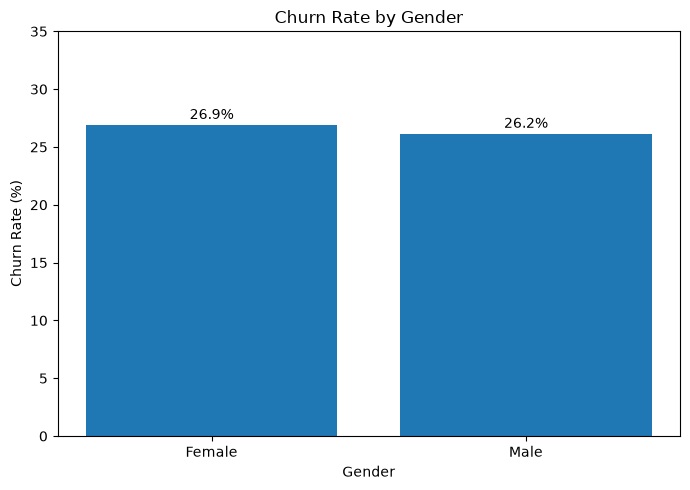

In [49]:
# Calculate churn rate by gender
gender_churn = (
    df.groupby("gender")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    gender_churn.index,
    gender_churn.values
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 35)
plt.tight_layout()
plt.show()

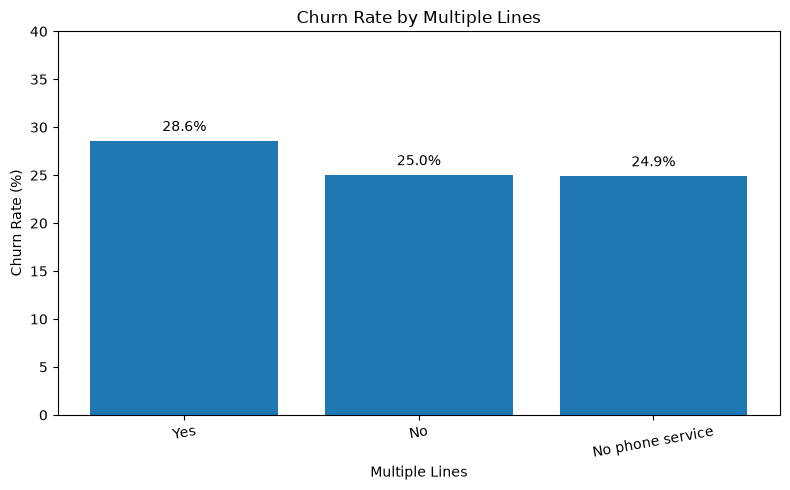

In [50]:
# Calculate churn rate by multiple lines
multiple_lines_churn = (
    df.groupby("MultipleLines")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(8, 5))

bars = plt.bar(
    multiple_lines_churn.index,
    multiple_lines_churn.values
)

plt.title("Churn Rate by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=10)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 40)
plt.tight_layout()
plt.show()

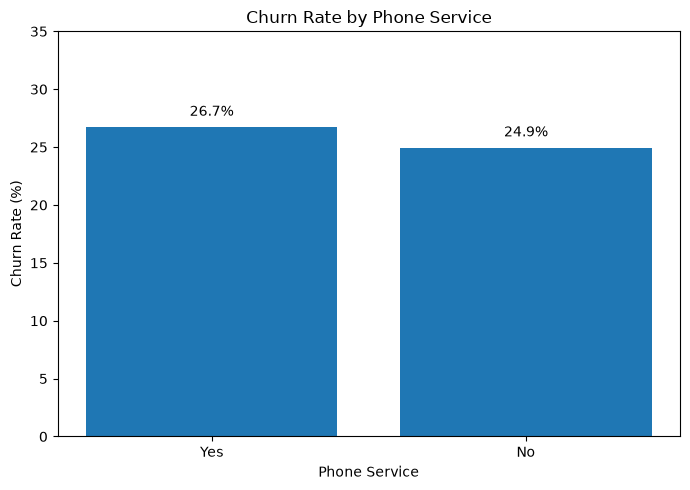

In [51]:
# Calculate churn rate by phone service
phone_churn = (
    df.groupby("PhoneService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    phone_churn.index,
    phone_churn.values
)

plt.title("Churn Rate by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 35)
plt.tight_layout()
plt.show()

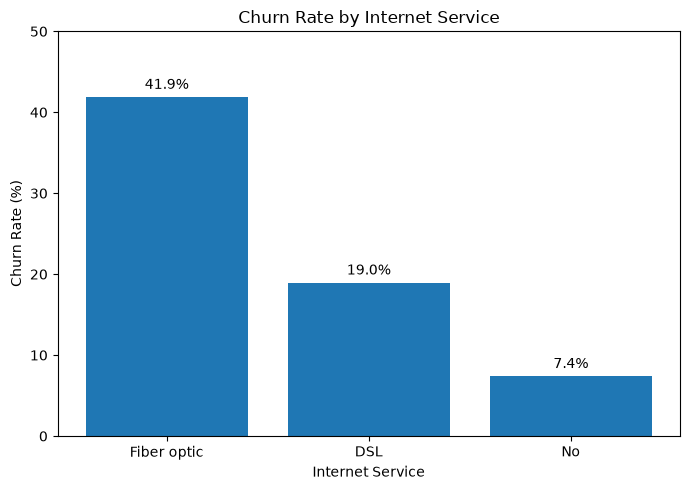

In [52]:
# Calculate churn rate by internet service
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    internet_churn.index,
    internet_churn.values
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

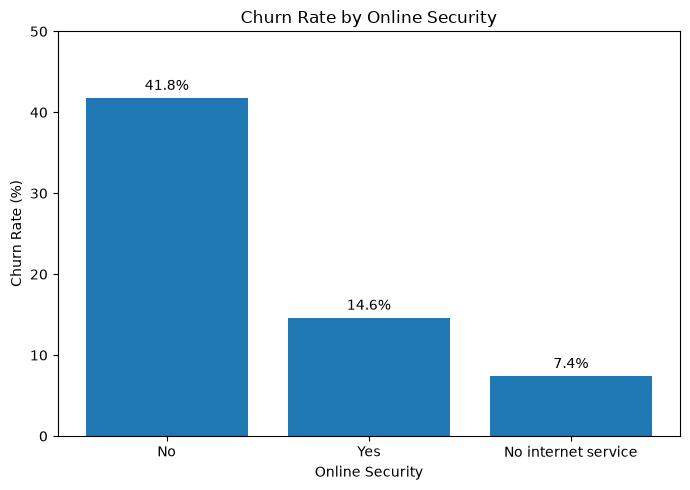

In [53]:
# Calculate churn rate by online security
security_churn = (
    df.groupby("OnlineSecurity")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    security_churn.index,
    security_churn.values
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

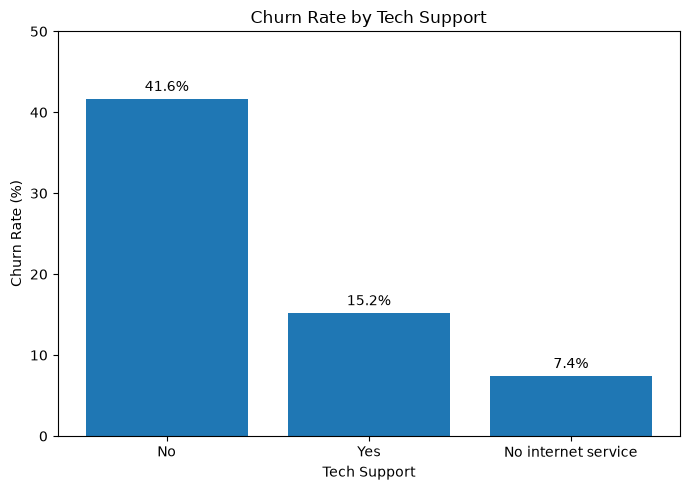

In [54]:
# Calculate churn rate by tech support
support_churn = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Plot the results
plt.figure(figsize=(7, 5))

bars = plt.bar(
    support_churn.index,
    support_churn.values
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}%",
        ha="center"
    )

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

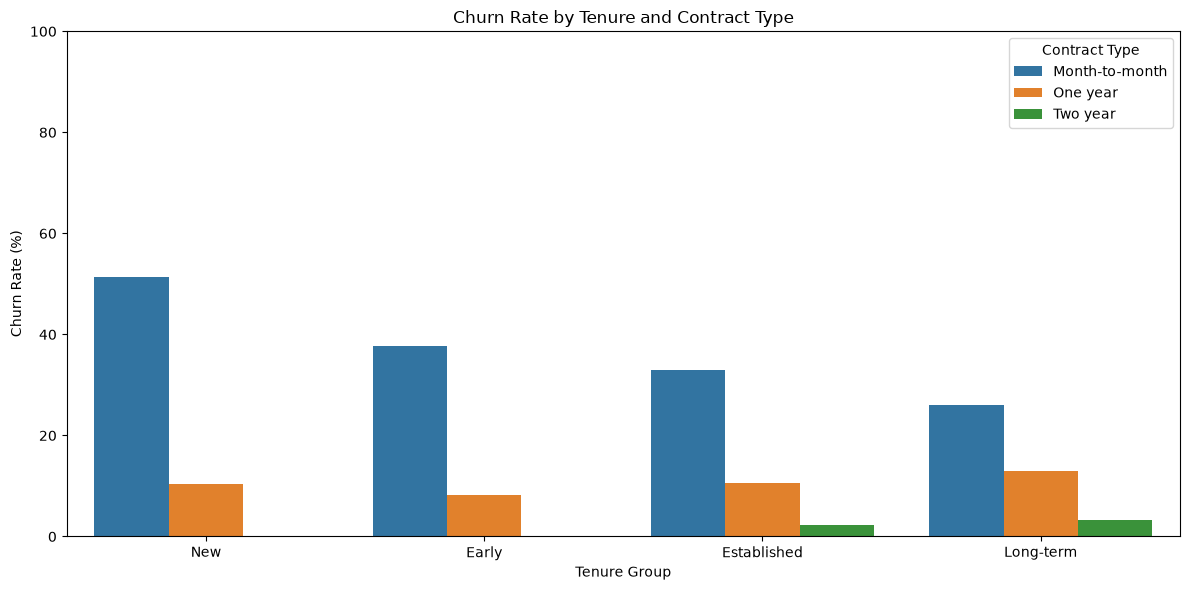

In [56]:
# Calculate churn rate by tenure and contract type
tenure_contract_churn = (
    df.assign(
        ChurnFlag=df["Churn"].map({"Yes": 1, "No": 0})
    )
    .groupby(["TenureGroup", "Contract"], observed=True)["ChurnFlag"]
    .mean()
    .mul(100)
    .reset_index(name="ChurnRate")
)

# Plot the results
plt.figure(figsize=(12, 6))

sns.barplot(
    data=tenure_contract_churn,
    x="TenureGroup",
    y="ChurnRate",
    hue="Contract"
)

plt.title("Churn Rate by Tenure and Contract Type")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Contract Type")

plt.tight_layout()
plt.show()

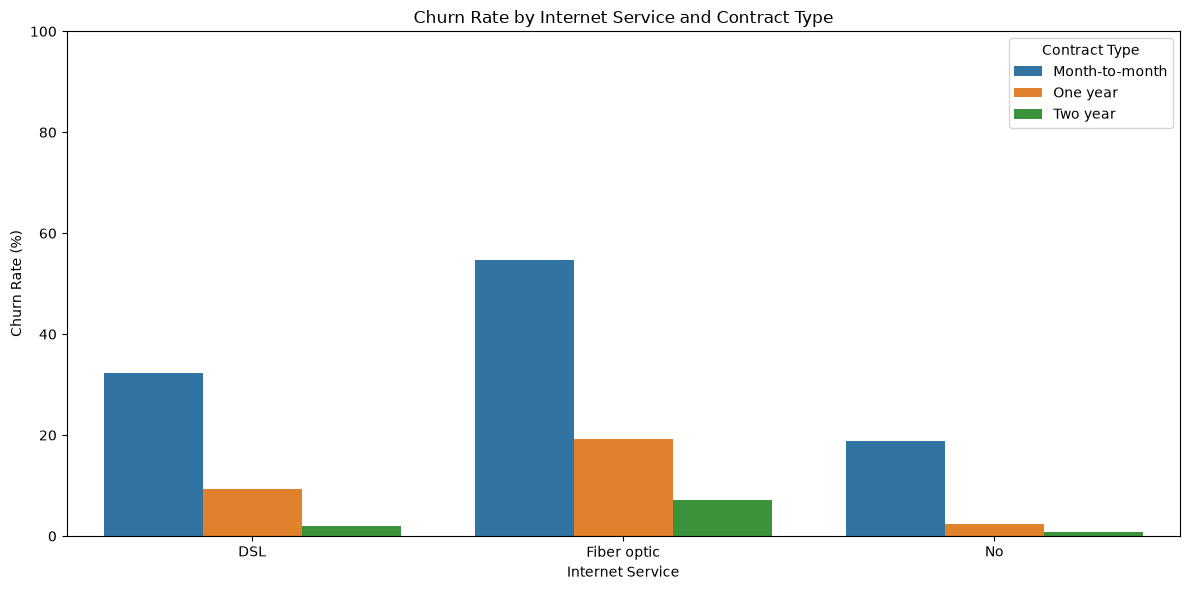

In [57]:
# Calculate churn rate by internet service and contract type
internet_contract_churn = (
    df.assign(
        ChurnFlag=df["Churn"].map({"Yes": 1, "No": 0})
    )
    .groupby(["InternetService", "Contract"], observed=True)["ChurnFlag"]
    .mean()
    .mul(100)
    .reset_index(name="ChurnRate")
)

# Plot the results
plt.figure(figsize=(12, 6))

sns.barplot(
    data=internet_contract_churn,
    x="InternetService",
    y="ChurnRate",
    hue="Contract"
)

plt.title("Churn Rate by Internet Service and Contract Type")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Contract Type")

plt.tight_layout()
plt.show()

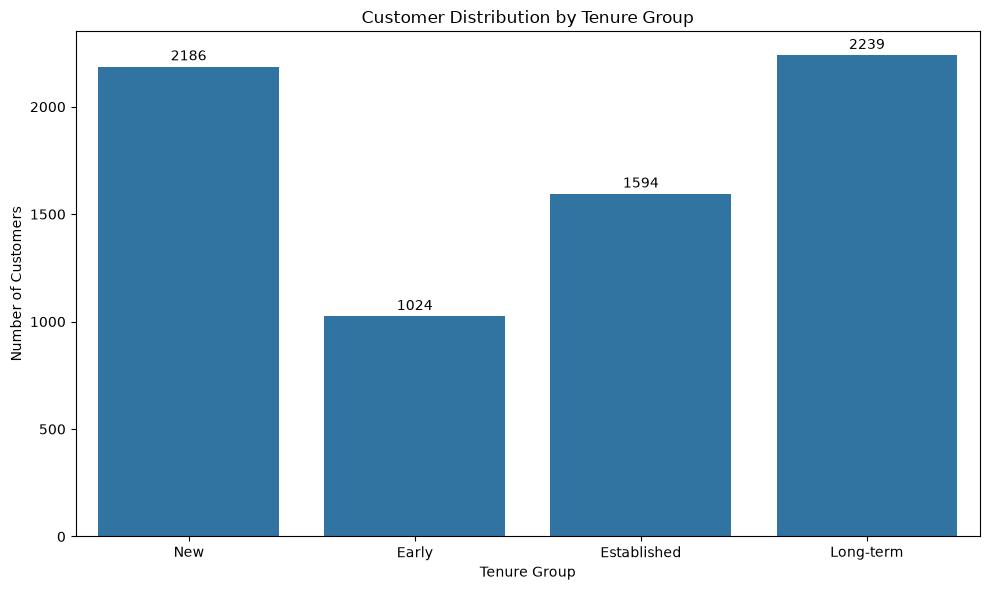

In [58]:
# Count customers in each tenure group
tenure_distribution = df["TenureGroup"].value_counts().sort_index()

# Plot customer distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    x=tenure_distribution.index,
    y=tenure_distribution.values
)

plt.title("Customer Distribution by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")

for i, value in enumerate(tenure_distribution.values):
    plt.text(i, value + 30, str(value), ha="center")

plt.tight_layout()
plt.show()

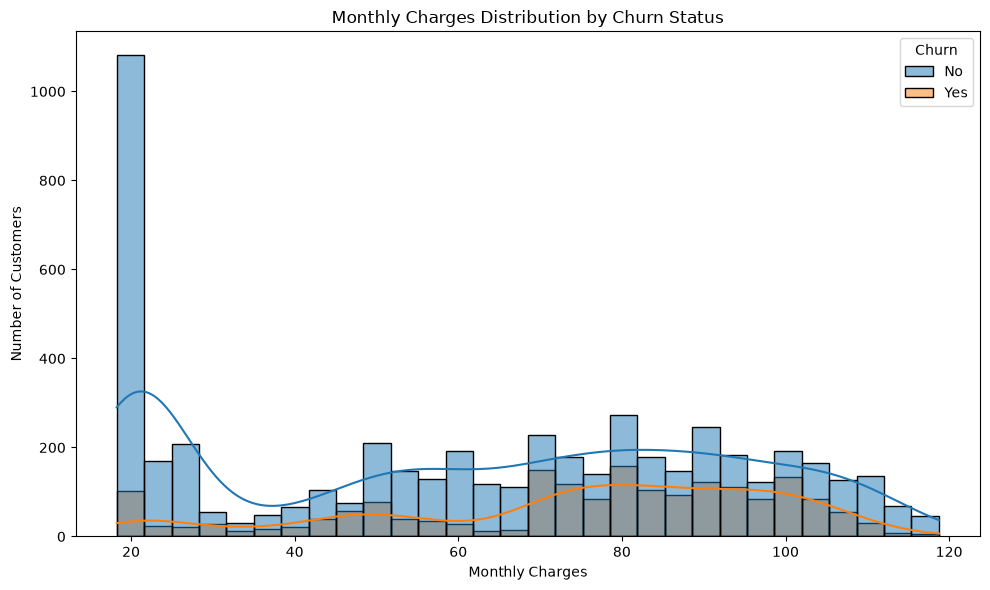

In [59]:
# Plot monthly charges distribution by churn status
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

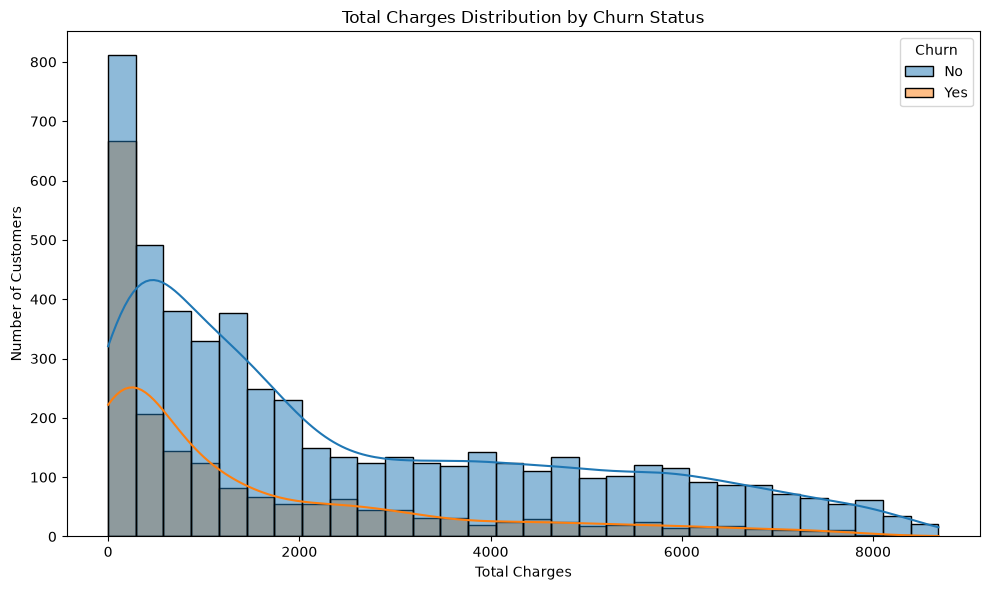

In [60]:
# Plot total charges distribution by churn status
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="TotalCharges",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Total Charges Distribution by Churn Status")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

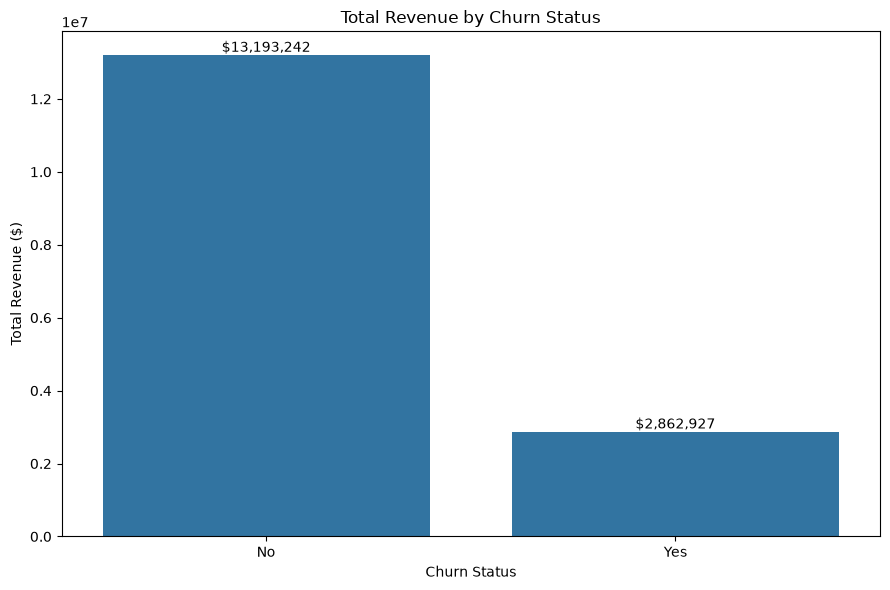

In [61]:
# Calculate total revenue by churn status
revenue_by_churn = df.groupby("Churn")["TotalCharges"].sum()

# Plot revenue by churn status
plt.figure(figsize=(9, 6))

sns.barplot(
    x=revenue_by_churn.index,
    y=revenue_by_churn.values
)

plt.title("Total Revenue by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Total Revenue ($)")

for i, value in enumerate(revenue_by_churn.values):
    plt.text(i, value + 100000, f"${value:,.0f}", ha="center")

plt.tight_layout()
plt.show()

In [62]:
# Check whether Logistic Regression model variables exist
print("Model:", "log_reg" in globals())
print("Predictions:", "y_pred" in globals())
print("Test labels:", "y_test" in globals())

Model: False
Predictions: False
Test labels: False


We haven't built the machine-learning models in this fresh notebook yet. So, before creating the confusion matrix, we need to train a Logistic Regression model.

We'll do this step by step. First, let's prepare the data for machine learning.
Step 1: Separate features and target
- Features (X): Customer information used to predict churn.
- Target (y): Whether the customer churned (Yes or No).

Why are we doing this?

We remove customerID because it is only an identifier, not a useful prediction feature. We also remove TenureGroup because it was created from the existing tenure column. The original tenure already contains that information.

In [63]:
# Separate input features and target variable
X = df.drop(columns=["customerID", "Churn", "TenureGroup"])
y = df["Churn"].map({"Yes": 1, "No": 0})

# Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Check target distribution
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


Step 2: Encode categorical columns
Machine-learning models require numerical inputs. We'll convert categorical columns into numerical columns using One-Hot Encoding.

In [64]:
# Convert categorical columns into numerical columns
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Display the encoded dataset
print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

# Display first five rows
X_encoded.head()

Original feature shape: (7043, 19)
Encoded feature shape: (7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


Step 3: Split the dataset into training and testing sets
We'll use:
- 80% training data to train the model.
- 20% testing data to evaluate its performance.
- stratify=y to preserve the original churn distribution in both sets.
- random_state=42 to make the split reproducible.

In [65]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 30)
Testing features: (1409, 30)
Training target: (5634,)
Testing target: (1409,)


In [67]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Scale the training and testing features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and train Logistic Regression model
log_reg = LogisticRegression(max_iter=2000)

log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Why use StandardScaler?

It brings numerical features onto a comparable scale. We fit the scaler only on training data to avoid data leakage.

In [68]:
# Generate predictions on the test dataset
y_pred = log_reg.predict(X_test_scaled)

print("Predictions generated successfully!")
print("First 10 predictions:", y_pred[:10])

Predictions generated successfully!
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]


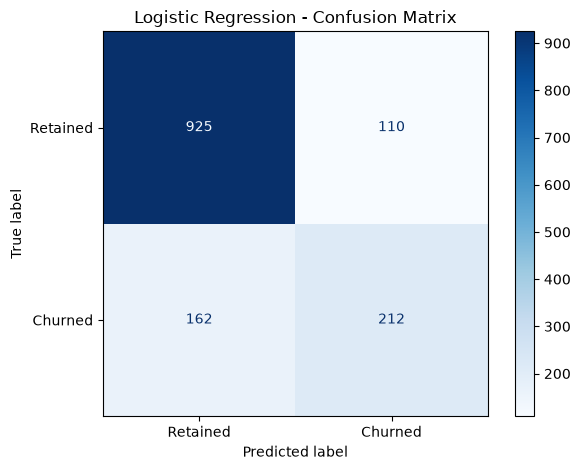

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display results
print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Retained", "Churned"]
))

Logistic Regression Performance
--------------------------------
Accuracy:  80.70%
Precision: 65.84%
Recall:    56.68%
F1-Score:  60.92%

Classification Report:
              precision    recall  f1-score   support

    Retained       0.85      0.89      0.87      1035
     Churned       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [71]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Why Random Forest?
- It can capture complex relationships between customer features.
- It does not require feature scaling.
- class_weight="balanced" helps account for the imbalance between retained and churned customers.

In [72]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate Random Forest performance metrics
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

# Display results
print("Random Forest Performance")
print("--------------------------------")
print(f"Accuracy:  {rf_accuracy * 100:.2f}%")
print(f"Precision: {rf_precision * 100:.2f}%")
print(f"Recall:    {rf_recall * 100:.2f}%")
print(f"F1-Score:  {rf_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Retained", "Churned"]
))

Random Forest Performance
--------------------------------
Accuracy:  77.00%
Precision: 55.95%
Recall:    62.83%
F1-Score:  59.19%

Classification Report:
              precision    recall  f1-score   support

    Retained       0.86      0.82      0.84      1035
     Churned       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.77      0.77      1409



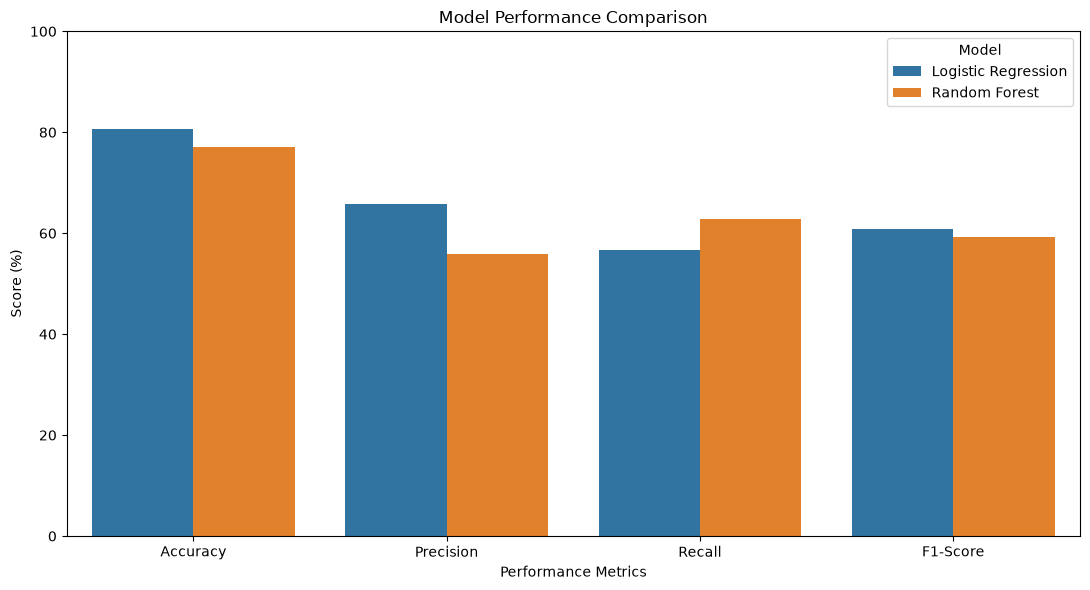

In [73]:
# Create model performance comparison dataframe
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ],
    "Random Forest": [
        rf_accuracy * 100,
        rf_precision * 100,
        rf_recall * 100,
        rf_f1 * 100
    ]
})

# Convert dataframe into plotting format
comparison_melted = model_comparison.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

# Plot model comparison
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Performance Comparison")
plt.xlabel("Performance Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

In [74]:
# Predict churn probabilities for all customers
all_customers_scaled = scaler.transform(X_encoded)

churn_probabilities = log_reg.predict_proba(all_customers_scaled)[:, 1]

# Create customer risk categories
risk_df = pd.DataFrame({
    "ChurnProbability": churn_probabilities
})

risk_df["RiskLevel"] = pd.cut(
    risk_df["ChurnProbability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

# Count customers in each risk category
risk_distribution = risk_df["RiskLevel"].value_counts().reindex(
    ["Low Risk", "Medium Risk", "High Risk"]
)

print("Customer Distribution by Churn Risk Level:")
print(risk_distribution)

Customer Distribution by Churn Risk Level:
RiskLevel
Low Risk       4370
Medium Risk    1631
High Risk      1042
Name: count, dtype: int64


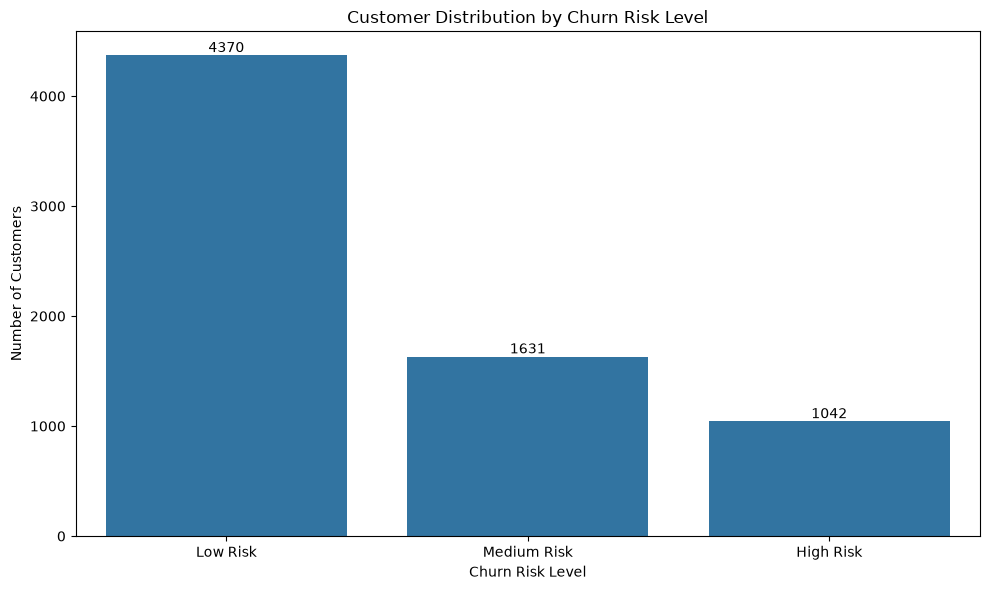

In [75]:
# Plot customer distribution by churn risk level
plt.figure(figsize=(10, 6))

sns.barplot(
    x=risk_distribution.index,
    y=risk_distribution.values
)

plt.title("Customer Distribution by Churn Risk Level")
plt.xlabel("Churn Risk Level")
plt.ylabel("Number of Customers")

for i, value in enumerate(risk_distribution.values):
    plt.text(i, value + 30, str(value), ha="center")

plt.tight_layout()
plt.show()

In [76]:
# Combine actual churn status with predicted risk levels
risk_df["ActualChurn"] = y.values

# Calculate actual churn rate for each risk category
actual_churn_by_risk = (
    risk_df.groupby("RiskLevel", observed=False)["ActualChurn"]
    .mean()
    .mul(100)
    .reset_index(name="ActualChurnRate")
)

print("Actual Churn Rate by Predicted Risk Level:")
print(actual_churn_by_risk)

Actual Churn Rate by Predicted Risk Level:
     RiskLevel  ActualChurnRate
0     Low Risk         9.816934
1  Medium Risk        42.427958
2    High Risk        71.785029


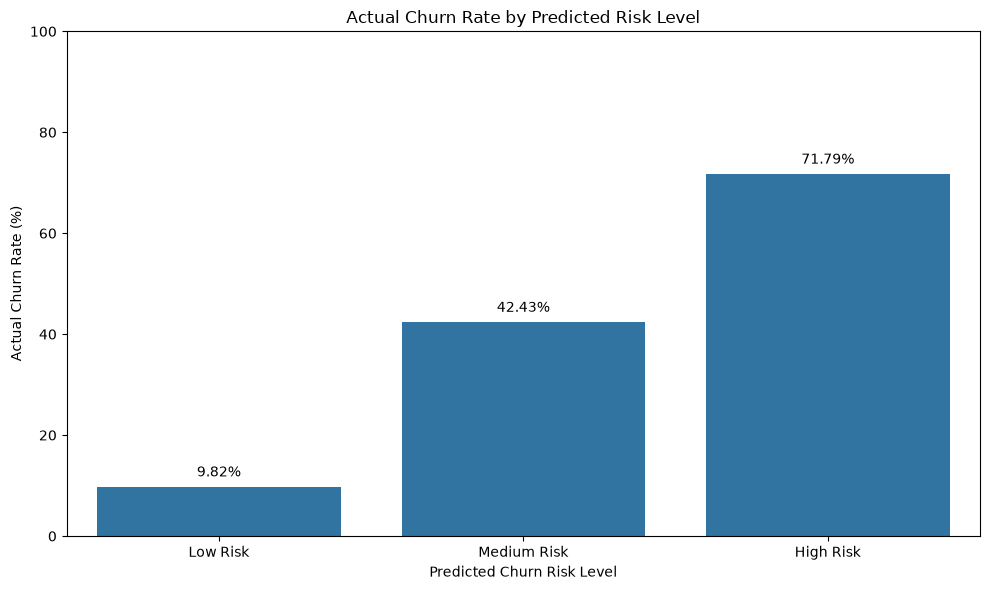

In [77]:
# Plot actual churn rate by predicted risk level
plt.figure(figsize=(10, 6))

sns.barplot(
    data=actual_churn_by_risk,
    x="RiskLevel",
    y="ActualChurnRate"
)

plt.title("Actual Churn Rate by Predicted Risk Level")
plt.xlabel("Predicted Churn Risk Level")
plt.ylabel("Actual Churn Rate (%)")
plt.ylim(0, 100)

# Add percentage labels
for i, value in enumerate(actual_churn_by_risk["ActualChurnRate"]):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [78]:
# Check existing model and prediction variables

print("LOGISTIC REGRESSION")
print("-------------------")
print("Model available:", "log_reg" in globals())

if "log_reg" in globals():
    print("Iterations used:", log_reg.n_iter_)

print("\nRANDOM FOREST")
print("-------------")
print("Model available:", "rf_model" in globals())

print("\nSCALING")
print("-------")
print("Scaler available:", "scaler" in globals())

print("\nPREDICTIONS")
print("-----------")
print("Logistic predictions:", "y_pred" in globals())
print("Random Forest predictions:", "rf_pred" in globals())

print("\nIMPROVED LOGISTIC REGRESSION")
print("----------------------------")
print("Improved pipeline available:", "logistic_model_scaled" in globals())

LOGISTIC REGRESSION
-------------------
Model available: True
Iterations used: [34]

RANDOM FOREST
-------------
Model available: True

SCALING
-------
Scaler available: True

PREDICTIONS
-----------
Logistic predictions: True
Random Forest predictions: True

IMPROVED LOGISTIC REGRESSION
----------------------------
Improved pipeline available: False


In [79]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (y_test, y_pred),
    "Random Forest": (y_test, rf_pred)
}

for name, (actual, predicted) in models.items():
    print(f"\n{name}")
    print("-" * 30)
    print("Accuracy :", round(accuracy_score(actual, predicted) * 100, 2), "%")
    print("Precision:", round(precision_score(actual, predicted) * 100, 2), "%")
    print("Recall   :", round(recall_score(actual, predicted) * 100, 2), "%")
    print("F1-score :", round(f1_score(actual, predicted) * 100, 2), "%")


Logistic Regression
------------------------------
Accuracy : 80.7 %
Precision: 65.84 %
Recall   : 56.68 %
F1-score : 60.92 %

Random Forest
------------------------------
Accuracy : 77.0 %
Precision: 55.95 %
Recall   : 62.83 %
F1-score : 59.19 %


In [80]:
# Generate churn probabilities for the test dataset

log_reg_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Logistic Regression probabilities:")
print(log_reg_prob[:10])

print("\nRandom Forest probabilities:")
print(rf_prob[:10])

Logistic Regression probabilities:
[0.04498216 0.68323418 0.05654172 0.40780551 0.02166567 0.60353786
 0.45187325 0.130925   0.00285167 0.39414547]

Random Forest probabilities:
[0.   0.89 0.12 0.47 0.01 0.59 0.42 0.14 0.01 0.56]


In [81]:
from sklearn.metrics import confusion_matrix

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

for threshold in thresholds:
    threshold_pred = (log_reg_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, threshold_pred
    ).ravel()

    precision = precision_score(y_test, threshold_pred, zero_division=0)
    recall = recall_score(y_test, threshold_pred, zero_division=0)

    print(f"\nThreshold: {threshold}")
    print("True Positives :", tp)
    print("False Positives:", fp)
    print("True Negatives :", tn)
    print("False Negatives:", fn)
    print("Precision      :", round(precision * 100, 2), "%")
    print("Recall         :", round(recall * 100, 2), "%")


Threshold: 0.3
True Positives : 282
False Positives: 261
True Negatives : 774
False Negatives: 92
Precision      : 51.93 %
Recall         : 75.4 %

Threshold: 0.4
True Positives : 250
False Positives: 191
True Negatives : 844
False Negatives: 124
Precision      : 56.69 %
Recall         : 66.84 %

Threshold: 0.5
True Positives : 212
False Positives: 110
True Negatives : 925
False Negatives: 162
Precision      : 65.84 %
Recall         : 56.68 %

Threshold: 0.6
True Positives : 149
False Positives: 61
True Negatives : 974
False Negatives: 225
Precision      : 70.95 %
Recall         : 39.84 %

Threshold: 0.7
True Positives : 65
False Positives: 24
True Negatives : 1011
False Negatives: 309
Precision      : 73.03 %
Recall         : 17.38 %


In [82]:
import pandas as pd

# Create a test dataset with actual churn status and predicted probability

risk_validation = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Churn_Probability": log_reg_prob
})

# Assign risk categories
risk_validation["Risk_Level"] = pd.cut(
    risk_validation["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

# Calculate actual churn rate for each risk category
risk_summary = risk_validation.groupby(
    "Risk_Level", observed=False
).agg(
    Customer_Count=("Actual_Churn", "count"),
    Actual_Churned=("Actual_Churn", "sum"),
    Actual_Churn_Rate=("Actual_Churn", "mean")
)

risk_summary["Actual_Churn_Rate"] = (
    risk_summary["Actual_Churn_Rate"] * 100
).round(2)

print(risk_summary)

             Customer_Count  Actual_Churned  Actual_Churn_Rate
Risk_Level                                                    
Low Risk                866              92              10.62
Medium Risk             333             133              39.94
High Risk               210             149              70.95


In [83]:
import os
import joblib

# Create a folder to store trained models
model_folder = "../models"
os.makedirs(model_folder, exist_ok=True)

# Save the trained Logistic Regression model
joblib.dump(log_reg, os.path.join(model_folder, "logistic_regression_model.pkl"))

# Save the fitted scaler
joblib.dump(scaler, os.path.join(model_folder, "standard_scaler.pkl"))

print("Model and scaler saved successfully!")
print("Saved files:")
print(os.listdir(model_folder))

Model and scaler saved successfully!
Saved files:
['logistic_regression_model.pkl', 'standard_scaler.pkl']


In [84]:
# Save the feature columns used during model training

joblib.dump(
    X_train.columns.tolist(),
    os.path.join(model_folder, "feature_columns.pkl")
)

print("Feature columns saved successfully!")
print("Total features:", len(X_train.columns))
print("\nFeature names:")
print(X_train.columns.tolist())

Feature columns saved successfully!
Total features: 30

Feature names:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [85]:
# Create a sample customer record

sample_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 12,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.50,
    "TotalCharges": 1026.00
}])

sample_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,12,Yes,No,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,85.5,1026.0


In [86]:
# Load the saved feature-column structure
feature_columns = joblib.load(
    os.path.join(model_folder, "feature_columns.pkl")
)

# Encode the sample customer
sample_encoded = pd.get_dummies(
    sample_customer,
    drop_first=True,
    dtype=int
)

# Align with the original training features
sample_encoded = sample_encoded.reindex(
    columns=feature_columns,
    fill_value=0
)

print("Original input features:", sample_customer.shape[1])
print("Encoded input features:", sample_encoded.shape[1])

print("\nEncoded customer data:")
display(sample_encoded)

Original input features: 19
Encoded input features: 30

Encoded customer data:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,12,85.5,1026.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [87]:
# Verify feature alignment

print("Feature count matches:",
      sample_encoded.shape[1] == len(feature_columns))

print("Feature order matches:",
      sample_encoded.columns.tolist() == feature_columns)

print("\nMissing values:", sample_encoded.isnull().sum().sum())

Feature count matches: True
Feature order matches: True

Missing values: 0


In [88]:
# Scale the customer data using the existing fitted scaler

sample_scaled = scaler.transform(sample_encoded)

# Generate churn prediction
churn_prediction = log_reg.predict(sample_scaled)[0]

# Generate churn probability
churn_probability = log_reg.predict_proba(sample_scaled)[0][1]

# Display prediction
print("Customer Churn Prediction")
print("-------------------------")
print("Prediction:", "Yes - Likely to Churn" if churn_prediction == 1 else "No - Likely to Stay")
print("Churn Probability:", round(churn_probability * 100, 2), "%")

Customer Churn Prediction
-------------------------
Prediction: No - Likely to Stay
Churn Probability: 9.13 %


In [89]:
# Assign customer risk category

if churn_probability < 0.30:
    risk_level = "Low Risk"
elif churn_probability < 0.60:
    risk_level = "Medium Risk"
else:
    risk_level = "High Risk"

print("Customer Risk Assessment")
print("------------------------")
print("Churn Probability:", round(churn_probability * 100, 2), "%")
print("Risk Level:", risk_level)

Customer Risk Assessment
------------------------
Churn Probability: 9.13 %
Risk Level: Low Risk


In [90]:
test_customers = pd.DataFrame([
    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 60,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Credit card (automatic)",
        "MonthlyCharges": 65.00,
        "TotalCharges": 3900.00
    },
    {
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "No",
        "Dependents": "No",
        "tenure": 24,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "DSL",
        "OnlineSecurity": "No",
        "OnlineBackup": "Yes",
        "DeviceProtection": "No",
        "TechSupport": "Yes",
        "StreamingTV": "Yes",
        "StreamingMovies": "No",
        "Contract": "One year",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 70.00,
        "TotalCharges": 1680.00
    },
    {
        "gender": "Male",
        "SeniorCitizen": 1,
        "Partner": "No",
        "Dependents": "No",
        "tenure": 2,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "Yes",
        "StreamingMovies": "Yes",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 95.00,
        "TotalCharges": 190.00
    }
])

print("Test customers created:", len(test_customers))
display(test_customers)

Test customers created: 3


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,Yes,60,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Credit card (automatic),65.0,3900.0
1,Male,0,No,No,24,Yes,No,DSL,No,Yes,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),70.0,1680.0
2,Male,1,No,No,2,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.0,190.0


In [91]:
# Encode the three test customers

test_encoded = pd.get_dummies(
    test_customers,
    drop_first=True,
    dtype=int
)

# Align features with the training structure
test_encoded = test_encoded.reindex(
    columns=feature_columns,
    fill_value=0
)

# Scale customer data
test_scaled = scaler.transform(test_encoded)

# Generate predictions and probabilities
test_predictions = log_reg.predict(test_scaled)
test_probabilities = log_reg.predict_proba(test_scaled)[:, 1]

# Assign risk categories
test_risks = []

for probability in test_probabilities:
    if probability < 0.30:
        test_risks.append("Low Risk")
    elif probability < 0.60:
        test_risks.append("Medium Risk")
    else:
        test_risks.append("High Risk")

# Create results table
test_results = pd.DataFrame({
    "Customer": ["Customer 1", "Customer 2", "Customer 3"],
    "Churn Prediction": [
        "Yes" if prediction == 1 else "No"
        for prediction in test_predictions
    ],
    "Churn Probability (%)": (
        test_probabilities * 100
    ).round(2),
    "Risk Level": test_risks
})

display(test_results)

,Customer,Churn Prediction,Churn Probability (%),Risk Level
0,Customer 1,No,0.66,Low Risk
1,Customer 2,No,9.02,Low Risk
2,Customer 3,Yes,77.97,High Risk


In [92]:
def predict_customer_churn(customer_data):

    # Convert customer data into a DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Encode categorical features
    encoded_data = pd.get_dummies(
        customer_df,
        drop_first=True,
        dtype=int
    )

    # Align with training features
    encoded_data = encoded_data.reindex(
        columns=feature_columns,
        fill_value=0
    )

    # Scale the data
    scaled_data = scaler.transform(encoded_data)

    # Predict churn
    prediction = log_reg.predict(scaled_data)[0]

    # Calculate churn probability
    probability = log_reg.predict_proba(scaled_data)[0][1]

    # Assign risk level
    if probability < 0.30:
        risk = "Low Risk"
    elif probability < 0.60:
        risk = "Medium Risk"
    else:
        risk = "High Risk"

    # Return results
    return {
        "Churn Prediction": "Yes" if prediction == 1 else "No",
        "Churn Probability (%)": round(probability * 100, 2),
        "Risk Level": risk
    }

print("Customer churn prediction function created successfully!")

Customer churn prediction function created successfully!


In [93]:
# Test the reusable prediction function

sample_result = predict_customer_churn(
    sample_customer.iloc[0].to_dict()
)

print("Reusable Function Test")
print("----------------------")

for key, value in sample_result.items():
    print(f"{key}: {value}")

Reusable Function Test
----------------------
Churn Prediction: No
Churn Probability (%): 9.13
Risk Level: Low Risk


In [94]:
# Extract Logistic Regression feature coefficients

coefficient_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_reg.coef_[0]
})

# Calculate absolute coefficient values
coefficient_df["Importance"] = (
    coefficient_df["Coefficient"].abs()
)

# Sort by importance
coefficient_df = coefficient_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Churn-Related Features")
print("-----------------------------")

display(coefficient_df.head(15))

Top 15 Churn-Related Features
-----------------------------


,Feature,Coefficient,Importance
1,tenure,-1.236528,1.236528
2,MonthlyCharges,-0.920153,0.920153
10,InternetService_Fiber optic,0.776154,0.776154
25,Contract_Two year,-0.586859,0.586859
3,TotalCharges,0.514285,0.514285
24,Contract_One year,-0.285509,0.285509
23,StreamingMovies_Yes,0.257227,0.257227
21,StreamingTV_Yes,0.257144,0.257144
9,MultipleLines_Yes,0.216167,0.216167
26,PaperlessBilling_Yes,0.182034,0.182034


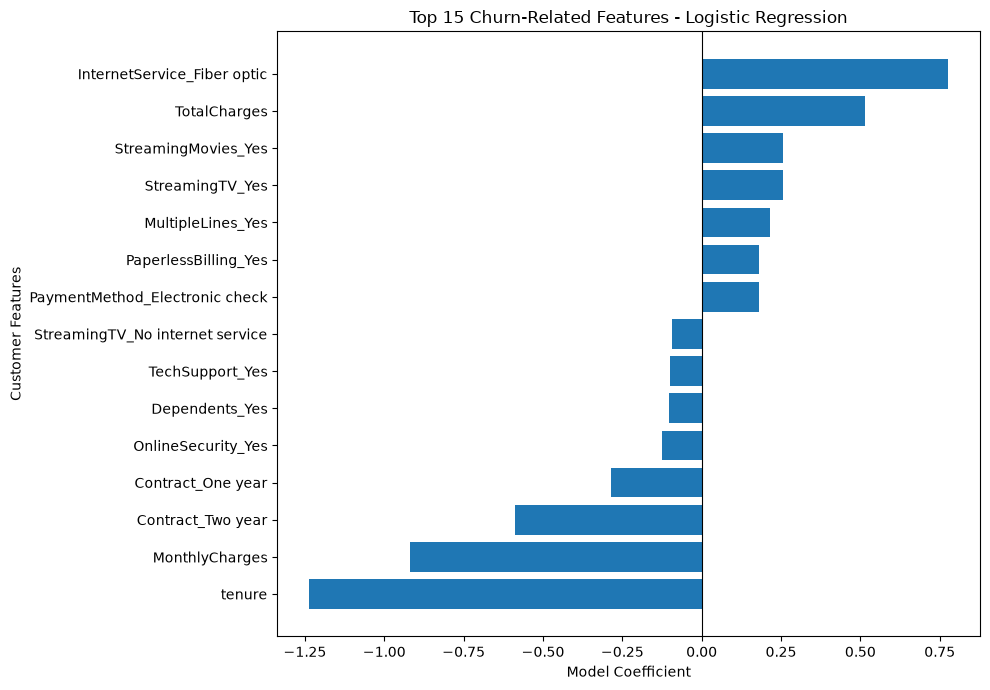

In [95]:
import matplotlib.pyplot as plt

top_features = coefficient_df.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Top 15 Churn-Related Features - Logistic Regression")
plt.xlabel("Model Coefficient")
plt.ylabel("Customer Features")

plt.tight_layout()
plt.show()

In [96]:
# Compare monthly charges by churn status

monthly_charge_analysis = df.groupby("Churn")[
    "MonthlyCharges"
].agg(["mean", "median", "count"])

print("Monthly Charges by Churn Status")
display(monthly_charge_analysis)

Monthly Charges by Churn Status


,mean,median,count
Churn,,,
No,61.265124,64.425,5174
Yes,74.441332,79.650,1869


In [97]:
# Check correlation among numerical features

correlation_data = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

print("Correlation Matrix")
display(correlation_data.corr().round(3))

Correlation Matrix


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


In [99]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 5.4 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [100]:
import statsmodels
print("Statsmodels version:", statsmodels.__version__)

Statsmodels version: 0.15.0


In [101]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical features
numerical_features = X_train[
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

# Calculate VIF
vif_df = pd.DataFrame({
    "Feature": numerical_features.columns,
    "VIF": [
        variance_inflation_factor(
            numerical_features.values, i
        )
        for i in range(numerical_features.shape[1])
    ]
})

display(vif_df.round(3))

,Feature,VIF
0,tenure,5.931
1,MonthlyCharges,3.230
2,TotalCharges,9.683


In [102]:
retention_strategies = pd.DataFrame({
    "Churn Driver": [
        "Low Customer Tenure",
        "Month-to-month Contract",
        "Fiber Optic Service",
        "Electronic Check Payment",
        "Lack of Online Security",
        "Lack of Tech Support",
        "High Monthly Charges"
    ],
    "Observed Churn Pattern": [
        "New customers show higher churn",
        "42.7% churn rate",
        "41.9% churn rate",
        "45.3% churn rate",
        "41.8% churn rate",
        "41.6% churn rate",
        "Churned customers pay higher average monthly charges"
    ],
    "Recommended Strategy": [
        "Introduce onboarding and engagement programmes",
        "Offer incentives for longer-term contracts",
        "Investigate service quality and customer satisfaction",
        "Encourage automatic payment methods",
        "Promote online security packages",
        "Provide proactive technical assistance",
        "Review pricing and offer suitable service bundles"
    ]
})

display(retention_strategies)

,Churn Driver,Observed Churn Pattern,Recommended Strategy
0,Low Customer Tenure,New customers show higher churn,Introduce onboarding and engagement programmes
1,Month-to-month Contract,42.7% churn rate,Offer incentives for longer-term contracts
2,Fiber Optic Service,41.9% churn rate,Investigate service quality and customer satis...
3,Electronic Check Payment,45.3% churn rate,Encourage automatic payment methods
4,Lack of Online Security,41.8% churn rate,Promote online security packages
5,Lack of Tech Support,41.6% churn rate,Provide proactive technical assistance
6,High Monthly Charges,Churned customers pay higher average monthly c...,Review pricing and offer suitable service bundles


In [103]:
# Separate churned and retained customers
churned_customers = df[df["Churn"] == "Yes"]
retained_customers = df[df["Churn"] == "No"]

# Calculate revenue figures
total_revenue = df["TotalCharges"].sum()
churned_revenue = churned_customers["TotalCharges"].sum()
retained_revenue = retained_customers["TotalCharges"].sum()

# Calculate average revenue per churned customer
avg_churned_revenue = churned_customers["TotalCharges"].mean()

print("BUSINESS IMPACT ANALYSIS")
print("-" * 35)
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Revenue from Churned Customers: ${churned_revenue:,.2f}")
print(f"Revenue from Retained Customers: ${retained_revenue:,.2f}")
print(f"Average Revenue per Churned Customer: ${avg_churned_revenue:,.2f}")
print(f"Number of Churned Customers: {len(churned_customers)}")

BUSINESS IMPACT ANALYSIS
-----------------------------------
Total Revenue: $16,056,168.70
Revenue from Churned Customers: $2,862,926.90
Revenue from Retained Customers: $13,193,241.80
Average Revenue per Churned Customer: $1,531.80
Number of Churned Customers: 1869


In [104]:
# Potential revenue retention scenarios

retention_rates = [0.10, 0.20, 0.30]

for rate in retention_rates:
    customers_retained = len(churned_customers) * rate
    potential_revenue = churned_revenue * rate

    print(f"\nRetention Scenario: {rate:.0%}")
    print(f"Customers Retained: {customers_retained:.0f}")
    print(f"Potential Historical Revenue Retained: ${potential_revenue:,.2f}")


Retention Scenario: 10%
Customers Retained: 187
Potential Historical Revenue Retained: $286,292.69

Retention Scenario: 20%
Customers Retained: 374
Potential Historical Revenue Retained: $572,585.38

Retention Scenario: 30%
Customers Retained: 561
Potential Historical Revenue Retained: $858,878.07


### 1. Key Customer Churn Findings

The analysis of 7,043 telecom customers identified an overall churn rate of **26.54%**, with 1,869 customers leaving the service.

The major findings include:

- Month-to-month contract customers have the highest churn rate (42.7%).
- New customers show the highest churn rate among tenure groups (47.4%).
- Fiber optic customers have a churn rate of 41.9%.
- Electronic check users have the highest payment-method churn rate (45.3%).
- Customers without online security and technical support show higher churn rates (41.8% and 41.6%, respectively).
- Churned customers have higher average monthly charges ($74.44) than retained customers ($61.27).

### 2. Machine Learning Model Performance

Two classification models were developed and evaluated:

- **Logistic Regression:** 80.70% accuracy and 60.92% F1-score.
- **Random Forest:** 77.00% accuracy and 59.19% F1-score.

Logistic Regression achieved better accuracy, precision and F1-score, while Random Forest achieved higher recall. Logistic Regression was selected for the reusable customer churn prediction workflow.

### 3. Customer Retention Recommendations

The analysis suggests several potential retention strategies:

- Improve onboarding and engagement during the initial customer period.
- Encourage longer-term contracts through suitable incentives.
- Investigate fiber optic service quality and customer satisfaction.
- Promote convenient automatic payment methods.
- Improve awareness and availability of online security and technical support services.
- Review pricing and offer suitable service bundles.

### 4. Business Impact

The 1,869 churned customers account for approximately **$2.86 million in historical customer charges**, representing 17.83% of total historical revenue.

The illustrative 30% retention scenario corresponds to approximately **$858,878.07 in historical charges**. This scenario demonstrates the potential financial significance of customer retention, but it is not a forecast of future revenue or profit.

### 5. Conclusion

This project demonstrates how exploratory data analysis and machine learning can be combined to understand customer churn and support data-driven retention decisions. The Logistic Regression model provides a reusable workflow for predicting churn probabilities and categorizing customers into low-, medium- and high-risk groups.

The findings can help businesses identify customer segments that may require additional attention and develop targeted retention strategies. Overall, the project demonstrates the practical application of Python, data analysis, visualization and machine learning in solving a business problem.

### 6. Limitations and Future Improvements

- Model performance can be improved through hyperparameter tuning and feature selection.
- Additional customer behaviour and satisfaction data could improve predictions.
- Retention strategies should be tested through controlled experiments.
- The business impact estimates are based on historical charges and simplified retention assumptions.
- The model should be monitored and periodically retrained using newer customer data.